# Análisis de señales de ciclos de carga y descarga de baterías
## 1. Preparación de datos y entorno

Vamos a realizar la carga y exploración de los datos de la betería B0005, procedente del repoaitorio de la NASA. El objetivo es identificar los ciclos de carga y descarga, extraer posteriormente las señales de tensión, corriente y temperatura y representar su evolución temporal. Además, se organizarán los datos para facilitar los análisis posteriores de comparación de ciclos, degradación y filtrado

### Datos utilizados
- **Fuente:** NASA Prognostics Center of Excellence Data Repository.
- **Conjunto de datos:** *Battery Data Set*.
- **Referencia:** B. Saha y K. Goebel (2007), *Battery Data Set*, NASA Ames Research Center.
- **Batería seleccionada:** B0005.
- **Archivo original:** `B0005.mat` (MATLAB).
- **Enlace del repositorio:** https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/
- **Fecha de consulta:** 18 de noviembre de 2026.


In [1]:
import numpy as np # cálculos con vectores numéricos
import pandas as pd # tablas y recuentos
import matplotlib.pyplot as plt # gráficas
from scipy.io import loadmat # lectura del archivo MATLAB
from pathlib import Path # construcción de rutas a los archivos

print("Librerías importadas correctamente")

Librerías importadas correctamente


Seguidamente cargamos el archivo B0005.mat y visualizamos las variables

In [2]:
# Buscar el archivo tanto si se ejecuta desde la raíz del proyecto
# como si se ejecuta desde la carpeta notebooks.
posibles_rutas = [Path("datos/B0005.mat"), Path("../datos/B0005.mat")]
ruta = next((p for p in posibles_rutas if p.is_file()), None)

if ruta is None:
    raise FileNotFoundError(
        "No se encuentra B0005.mat. Comprueba que está en la carpeta datos/ "
        "y que has abierto el proyecto correcto en VS Code."
    )

print("Archivo encontrado en:", ruta.resolve())

datos = loadmat(ruta, simplify_cells=True)

# Mostrar las variables principales almacenadas en el archivo MATLAB
print("Variables del archivo:", list(datos.keys()))

Archivo encontrado en: C:\Lidia\UNIVERSIDAD\Tercero\Señales y Sistemas\Trabajo\Se-ales_Sistemas\datos\B0005.mat
Variables del archivo: ['__header__', '__version__', '__globals__', 'B0005']


Vemos comos claves principales:

```text
['__header__', '__version__', '__globals__', 'B0005']
```
Las tres primeras claves describen el archivo MATLAB y B0005 contiene la información de la batería.

## 2. Análisis de registros de la bateria
**1. Acceso a los registros de la bateria**

La estructura B0005 contiene el campo cycle que describe una operación experimental. 
Un registro no equivale necesariamente a un ciclo de descarga, porque también incluye cargas y mediciones de impedancia.

In [3]:
# Acceder a la información de la batería
bateria = datos["B0005"]

# Mostrar sus campos, para comprobar la estructura real
print("Campos de B0005:", list(bateria.keys()))

# Obtener los registros experimentales
ciclos = bateria["cycle"]

print("Número total de registros:", len(ciclos))

Campos de B0005: ['cycle']
Número total de registros: 616


En B0005.mat aparecen 616 registros en total.

**2. Contar las operaciones de carga, descarga e impedancia**

En cada registro existe un campo type que indica el tipo de operación: charge (carga), discharge (descarga) o impedance (ensayo de impedancia). Utilizaremos la carga y la descarga para analizar señales de tensión, corriente y temperatura.

In [4]:
# Obtener el tipo de cada registro y contar cuántos hay de cada clase
tipos = [ciclo["type"] for ciclo in ciclos]
recuento = pd.Series(tipos).value_counts()

print("Registros por tipo de operación:")
print(recuento)

print("\nComprobación (la suma debe coincidir con el total):")
print(recuento.sum(), "registros de", len(ciclos))

Registros por tipo de operación:
impedance    278
charge       170
discharge    168
Name: count, dtype: int64

Comprobación (la suma debe coincidir con el total):
616 registros de 616


Realizamos un conteo por tipo de registro para saber de que datos disponemos:
- Independencia: 278
- Carga: 170
- Descarga: 168

Por tanto, hay datos suficientes para estudiar el funcionamiento en carga y descarga y comparar posteriormente distintos estados de la batería.

**3. Comprobación rápida de la estructura de un registro**

Mostramos las claves realmente presentes en un registro de carga y uno de descarga, para poder analizar el dataset correctamente después.

In [5]:
# Seleccionar el primer registro de carga y de descarga
primer_carga = next(c for c in ciclos if c["type"] == "charge")
primer_descarga = next(c for c in ciclos if c["type"] == "discharge")

for nombre, registro in [("Carga", primer_carga), ("Descarga", primer_descarga)]:
    print(f"\n{nombre}:")
    print("Campos del registro:", list(registro.keys()))
    if "data" in registro and isinstance(registro["data"], dict):
        print("Campos de las mediciones:", list(registro["data"].keys()))


Carga:
Campos del registro: ['type', 'ambient_temperature', 'time', 'data']
Campos de las mediciones: ['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_charge', 'Voltage_charge', 'Time']

Descarga:
Campos del registro: ['type', 'ambient_temperature', 'time', 'data']
Campos de las mediciones: ['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time', 'Capacity']


**4. Separación de operaciones de carga y descarga**

Para trabajar con las señales temporales, separamos los registros por su tipo. Los ensayos de impedancia quedan fuera de este análisis inicial. También conservamos la posición original de cada registro para identificarlo sin confusiones.

In [6]:
# Guardar (índice original, registro), para no perder la referencia en el .mat
ciclos_carga = [(i, ciclo) for i, ciclo in enumerate(ciclos, start=1) if ciclo["type"] == "charge"]
ciclos_descarga = [(i, ciclo) for i, ciclo in enumerate(ciclos, start=1) if ciclo["type"] == "discharge"]

print("Ciclos de carga:", len(ciclos_carga))
print("Ciclos de descarga:", len(ciclos_descarga))
print("Primera descarga: registro original", ciclos_descarga[0][0])

Ciclos de carga: 170
Ciclos de descarga: 168
Primera descarga: registro original 2


**5. Inspección de un registro de descarga y de carga**

Comprobamos los nombres reales de los campos antes de extraer valores. En B0005.mat, la capacidad aparece como un valor único en la información de cada descarga; no es una serie temporal.

In [7]:
registro_descarga, primer_ciclo_descarga = ciclos_descarga[0]
registro_carga, primer_ciclo_carga = ciclos_carga[0]

print("Campos del primer ciclo de descarga:", list(primer_ciclo_descarga.keys()))
print("Señales de descarga:", list(primer_ciclo_descarga["data"].keys()))
print("Señales de carga:", list(primer_ciclo_carga["data"].keys()))

Campos del primer ciclo de descarga: ['type', 'ambient_temperature', 'time', 'data']
Señales de descarga: ['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time', 'Capacity']
Señales de carga: ['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_charge', 'Voltage_charge', 'Time']


## 3. Primera descarga
**1. Extraer las señales de la primera descarga**

Seleccionamos la primera descarga y convertimos tiempo, tensión, corriente y temperatura en vectores unidimensionales. Antes de graficar, comprobamos que sus longitudes coinciden y que todos sus valores son numéricos y finitos.

In [8]:
# Obtener las mediciones de la primera descarga
datos_ciclo = primer_ciclo_descarga["data"]

tiempo = np.asarray(datos_ciclo["Time"], dtype=float).flatten()
tension = np.asarray(datos_ciclo["Voltage_measured"], dtype=float).flatten()
corriente = np.asarray(datos_ciclo["Current_measured"], dtype=float).flatten()
temperatura = np.asarray(datos_ciclo["Temperature_measured"], dtype=float).flatten()

print("Mediciones de tiempo:", len(tiempo))
print("Mediciones de tensión:", len(tension))
print("Mediciones de corriente:", len(corriente))
print("Mediciones de temperatura:", len(temperatura))

assert len(tiempo) == len(tension) == len(corriente) == len(temperatura), "Las longitudes son diferentes"
assert np.isfinite(np.column_stack([tiempo, tension, corriente, temperatura])).all(), "Hay valores no válidos"
assert np.all(np.diff(tiempo) >= 0), "El tiempo no está ordenado"
print("Comprobaciones correctas")

Mediciones de tiempo: 197
Mediciones de tensión: 197
Mediciones de corriente: 197
Mediciones de temperatura: 197
Comprobaciones correctas


**2. Tiempo desde el comienzo de la descarga**

Para que el eje de las figuras sea fácil de interpretar, restamos el primer instante registrado: tiempo = tiempo - tiempo[0]. No alteramos los demás valores.

In [9]:
tiempo = tiempo - tiempo[0]
print("Tiempo inicial:", tiempo[0], "s")
print("Tiempo final:", round(tiempo[-1], 2), "s")

Tiempo inicial: 0.0 s
Tiempo final: 3690.23 s


**3. Tres gráficas del primer ciclo de descarga**

En las siguientes figuras se estudian por separado las señales de tensión, corriente y temperatura frente al tiempo. El objetivo aquí es describir la forma de las señales, no evaluar todavía la degradación. Se conservan los signos originales de la corriente.

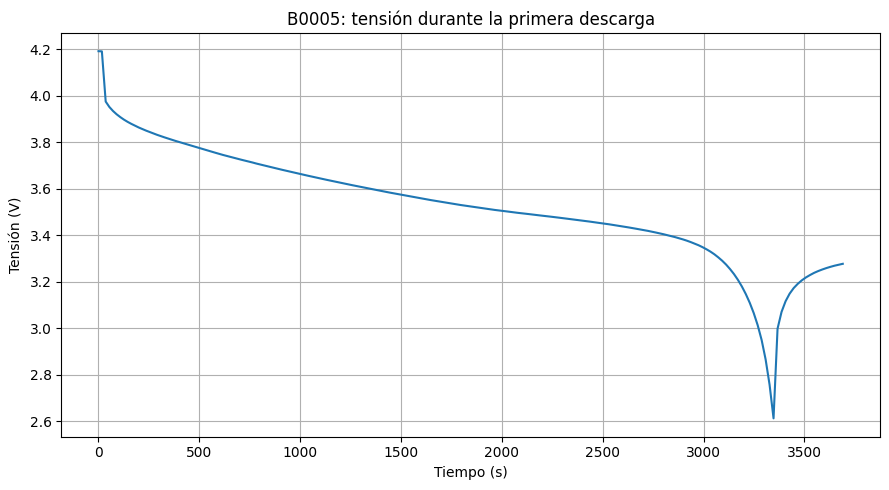

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(tiempo, tension)
plt.title("B0005: tensión durante la primera descarga")
plt.xlabel("Tiempo (s)")
plt.ylabel("Tensión (V)")
plt.grid(True)
plt.tight_layout()
plt.show()

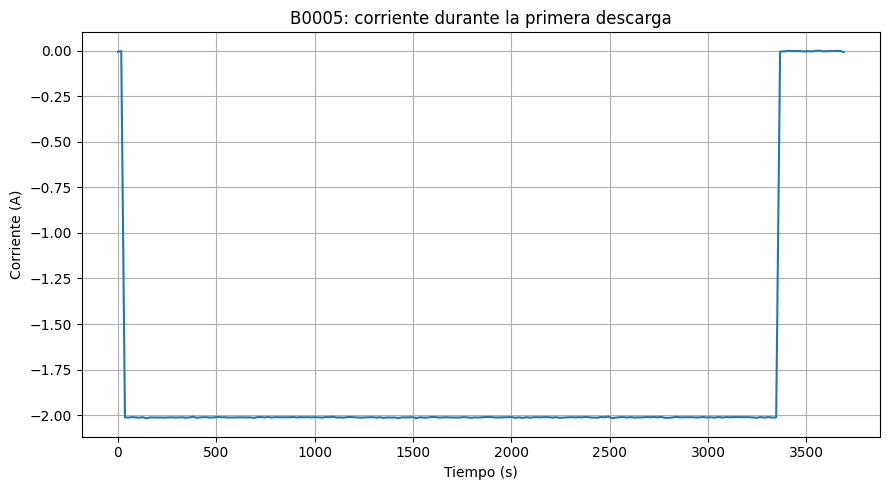

In [11]:
plt.figure(figsize=(9, 5))
plt.plot(tiempo, corriente)
plt.title("B0005: corriente durante la primera descarga")
plt.xlabel("Tiempo (s)")
plt.ylabel("Corriente (A)")
plt.grid(True)
plt.tight_layout()
plt.show()

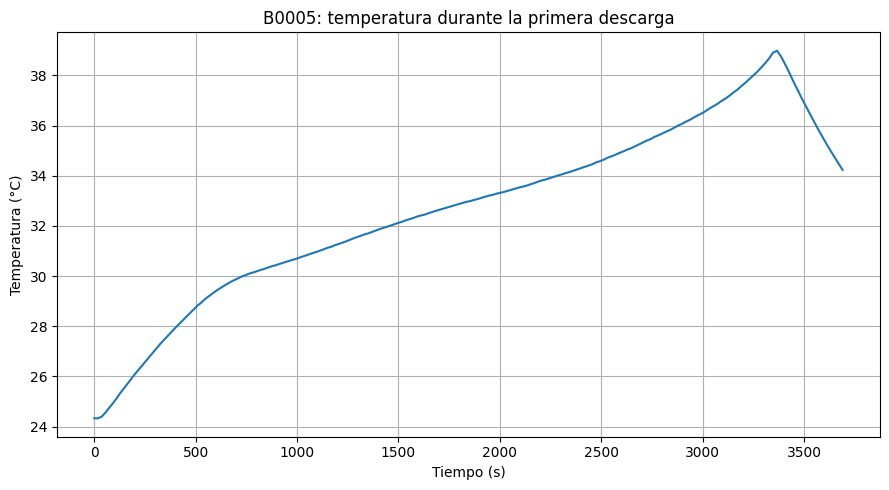

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(tiempo, temperatura)
plt.title("B0005: temperatura durante la primera descarga")
plt.xlabel("Tiempo (s)")
plt.ylabel("Temperatura (°C)")
plt.grid(True)
plt.tight_layout()
plt.show()

### Interpretación de las tres gráficas de la primera descarga

**1. Tensión frente al tiempo.** La tensión comienza cerca de 4,2 V y desciende progresivamente. Primero hay una caída rápida y, después, una disminución más suave. Cerca del final alcanza unos 2,6 V y luego se recupera parcialmente, hasta alrededor de 3,3 V. Esta subida final no significa una nueva carga: coincide con la interrupción de la corriente de descarga y la recuperación de tensión de la batería en reposo.

**2. Corriente frente al tiempo.** Durante casi toda la descarga, la corriente se mantiene alrededor de −2 A, como corresponde a una descarga aproximadamente constante. Hacia los 3350 s, pasa a estar cerca de 0 A. El registro continúa después, por lo que su duración completa no equivale a la duración de la descarga activa.

**3. Temperatura frente al tiempo.** La temperatura empieza cerca de 24,4 °C, aumenta durante la descarga y alcanza aproximadamente 39 °C. Después de interrumpirse la corriente, desciende. Esto es compatible con el calentamiento bajo carga y el enfriamiento posterior.

## 4. Comparar una carga con una descarga

Utilizaremos las señales de la primera descarga para compararlas con la primera carga, de nuevo separando las gráficas en tensión, corriente y tenperatura frente al tiempo. Cada curva empieza en su propio instante cero; por eso la duración puede ser distinta.

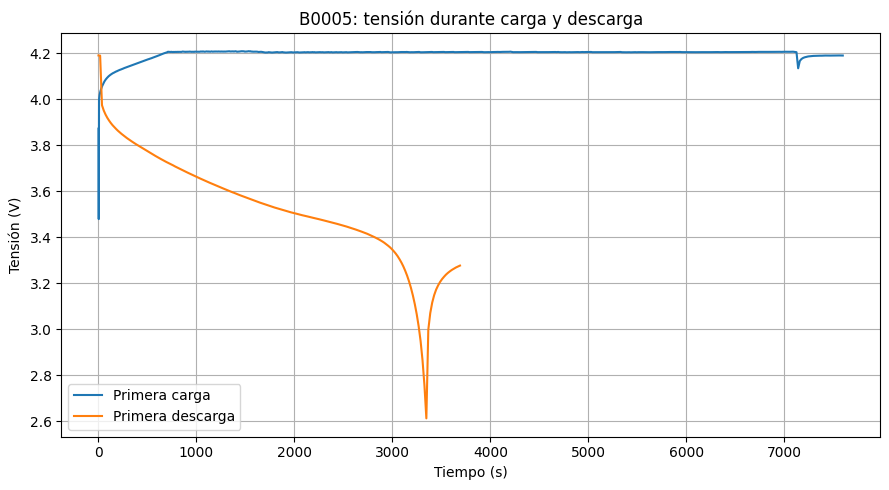

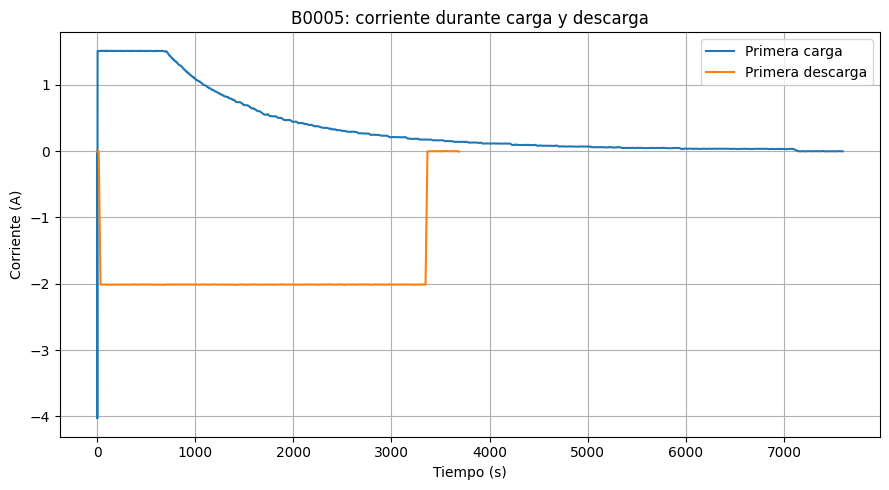

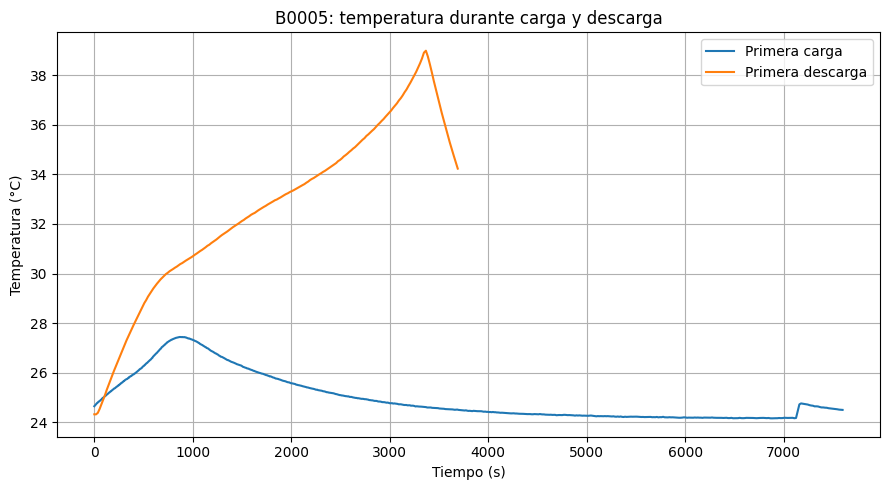

In [13]:
# Extraer un ciclo de carga completo
datos_carga = primer_ciclo_carga["data"]
tiempo_carga = np.asarray(datos_carga["Time"], dtype=float).flatten()
tension_carga = np.asarray(datos_carga["Voltage_measured"], dtype=float).flatten()
corriente_carga = np.asarray(datos_carga["Current_measured"], dtype=float).flatten()
temperatura_carga = np.asarray(datos_carga["Temperature_measured"], dtype=float).flatten()

assert len(tiempo_carga) == len(tension_carga) == len(corriente_carga) == len(temperatura_carga)
assert np.isfinite(np.column_stack([tiempo_carga, tension_carga, corriente_carga, temperatura_carga])).all()
tiempo_carga = tiempo_carga - tiempo_carga[0]

# Dibujar una figura por magnitud, con carga y descarga superpuestas
for nombre, carga, descarga, unidad in [
    ("Tensión", tension_carga, tension, "V"),
    ("Corriente", corriente_carga, corriente, "A"),
    ("Temperatura", temperatura_carga, temperatura, "°C")
]:
    plt.figure(figsize=(9, 5))
    plt.plot(tiempo_carga, carga, label="Primera carga")
    plt.plot(tiempo, descarga, label="Primera descarga")
    plt.title(f"B0005: {nombre.lower()} durante carga y descarga")
    plt.xlabel("Tiempo (s)")
    plt.ylabel(f"{nombre} ({unidad})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### Interpretación de las tres comparaciones entre carga y descarga

**4. Tensión durante carga y descarga.** En la carga, la tensión aumenta y se mantiene cerca de 4,2 V durante una parte prolongada del registro. En la descarga, disminuye de manera progresiva. Esta diferencia ayuda a reconocer ambos procesos; los tiempos de cada curva se cuentan desde el inicio de su propio registro y no son una secuencia continua.

**5. Corriente durante carga y descarga.** La corriente de carga aparece positiva: primero se mantiene relativamente estable y después disminuye hacia cero, un comportamiento compatible con un proceso de carga de corriente constante y tensión constante. La descarga aparece cerca de −2 A hasta que se detiene. El signo depende de la convención usada en el conjunto de datos y se ha mantenido sin modificar.

**6. Temperatura durante carga y descarga.** Durante la primera carga, la temperatura sube hasta unos 27,5 °C y luego desciende. Durante la primera descarga, crece de forma mucho más pronunciada, hasta unos 39 °C. Esto describe estos dos registros concretos; no significa que toda descarga caliente siempre más que toda carga, porque pueden intervenir las condiciones de funcionamiento.

## 5. Preparar las tablas comunes y guardar archivos

Se crean dos CSV:

- mediciones.csv: una fila por instante registrado, con tensión, corriente, temperatura y los identificadores de batería y operación.
- resumen_ciclos.csv: una fila por carga o descarga, con duración y capacidad cuando exista. El campo numero_descarga cuenta únicamente descargas; registro_original permite localizar el evento en el archivo .mat.

La capacidad no se repite en cada instante, porque es un valor asociado a una descarga completa.

In [14]:
# Crear las tablas con todos los registros de carga y descarga
filas_mediciones = []
filas_resumen = []
numero_carga = 0
numero_descarga = 0

for registro_original, ciclo in enumerate(ciclos, start=1):
    tipo = ciclo["type"]
    if tipo not in ("charge", "discharge"):
        continue

    if tipo == "charge":
        numero_carga += 1
        numero_tipo = numero_carga
        n_descarga = None
    else:
        numero_descarga += 1
        numero_tipo = numero_descarga
        n_descarga = numero_descarga

    d = ciclo["data"]
    t = np.asarray(d["Time"], dtype=float).flatten()
    v = np.asarray(d["Voltage_measured"], dtype=float).flatten()
    i = np.asarray(d["Current_measured"], dtype=float).flatten()
    temp = np.asarray(d["Temperature_measured"], dtype=float).flatten()

    # Saltar registros incompletos o con medidas no válidas
    if not (len(t) > 0 and len(t) == len(v) == len(i) == len(temp)):
        print("Registro omitido por longitudes:", registro_original)
        continue
    if not np.isfinite(np.column_stack([t, v, i, temp])).all() or np.any(np.diff(t) < 0):
        print("Registro omitido por medidas no válidas:", registro_original)
        continue

    t = t - t[0]
    # La capacidad del archivo está definida por descarga, no por muestra
    capacidad = float(d["Capacity"]) if tipo == "discharge" and "Capacity" in d else np.nan

    # Distinguimos el tiempo total registrado de la fase con corriente apreciable.
    # Umbral simple y explícito: |corriente| >= 0.5 A; es una estimación
    # basada en las muestras disponibles, no una detección física exacta.
    muestras_activas = np.flatnonzero(np.abs(i) >= 0.5)
    duracion_activa = (float(t[muestras_activas[-1]] - t[muestras_activas[0]])
                       if len(muestras_activas) >= 2 else np.nan)

    for instante, voltaje, intensidad, grados in zip(t, v, i, temp):
        filas_mediciones.append({
            "bateria": "B0005", "registro_original": registro_original,
            "tipo": tipo, "numero_tipo": numero_tipo,
            "tiempo_s": instante, "tension_V": voltaje,
            "corriente_A": intensidad, "temperatura_C": grados
        })

    filas_resumen.append({
        "bateria": "B0005", "registro_original": registro_original,
        "tipo": tipo, "numero_tipo": numero_tipo,
        "numero_descarga": n_descarga, "duracion_s": float(t[-1]),
        "duracion_activa_s": duracion_activa, "capacidad_Ah": capacidad
    })

mediciones = pd.DataFrame(filas_mediciones)
resumen_ciclos = pd.DataFrame(filas_resumen)

print("Mediciones:", mediciones.shape)
print("Resumen de ciclos:", resumen_ciclos.shape)
print("Ciclos con datos exportables por tipo:")
print(resumen_ciclos["tipo"].value_counts())
print("Primeras filas del resumen:")
display(resumen_ciclos.head())

Mediciones: (591458, 8)
Resumen de ciclos: (338, 8)
Ciclos con datos exportables por tipo:
tipo
charge       170
discharge    168
Name: count, dtype: int64
Primeras filas del resumen:


,bateria,registro_original,tipo,numero_tipo,numero_descarga,duracion_s,duracion_activa_s,capacidad_Ah
0,B0005,1,charge,1,NaN,7597.875,1875.015,NaN
1,B0005,2,discharge,1,1.0,3690.234,3311.234,1.856487
2,B0005,3,charge,2,NaN,10516.000,4416.984,NaN
3,B0005,4,discharge,2,2.0,3672.344,3293.125,1.846327
4,B0005,5,charge,3,NaN,10484.547,4388.656,NaN


**Diferencia entre duración total y duración activa**

La duracion total (duracion_s) indica todo el tiempo que cubre el registro, desde la primera hasta la última muestra. Puede incluir un tramo de reposo posterior al corte de corriente.

La duraccion activa (duracion_activa_s) estima el intervalo entre la primera y la última muestra con |corriente| ≥ 0,5 A. Es un criterio práctico para separar la fase activa de los tramos cercanos a 0 A. No debe interpretarse como una medida exacta del instante de corte, porque depende del muestreo y del umbral; se usa por igual en todos los ciclos para poder compararlos. En algunos registros el umbral podría no representar exactamente la fase buscada, así que debe revisarse junto con la curva de corriente.

Conservaremos mediciones.csv porque ayuda a interpretar la recuperación de tensión y el enfriamiento. Tampoco alteramos el signo de la corriente.

In [15]:
# Comparar ambas duraciones en el primer ciclo de descarga
primera = resumen_ciclos[(resumen_ciclos["tipo"] == "discharge") &
                        (resumen_ciclos["numero_descarga"] == 1)].iloc[0]
print("Primera descarga - duración registrada (s):", round(primera["duracion_s"], 2))
print("Primera descarga - duración activa estimada (s):", round(primera["duracion_activa_s"], 2))
print("Diferencia (s):", round(primera["duracion_s"] - primera["duracion_activa_s"], 2))

Primera descarga - duración registrada (s): 3690.23
Primera descarga - duración activa estimada (s): 3311.23
Diferencia (s): 379.0


In [16]:
# La carpeta del proyecto es la carpeta que contiene datos/B0005.mat
carpeta_proyecto = ruta.resolve().parent.parent
carpeta_csv = carpeta_proyecto / "datos_procesados"
carpeta_graficas = carpeta_proyecto / "graficas"
carpeta_csv.mkdir(exist_ok=True)
carpeta_graficas.mkdir(exist_ok=True)

mediciones.to_csv(carpeta_csv / "mediciones.csv", index=False)
resumen_ciclos.to_csv(carpeta_csv / "resumen_ciclos.csv", index=False)

for nombre, y, unidad in [
    ("tension", tension, "Tensión (V)"),
    ("corriente", corriente, "Corriente (A)"),
    ("temperatura", temperatura, "Temperatura (°C)")
]:
    plt.figure(figsize=(9, 5))
    plt.plot(tiempo, y)
    plt.title(f"B0005: {nombre} en la primera descarga")
    plt.xlabel("Tiempo (s)")
    plt.ylabel(unidad)
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(carpeta_graficas / f"B0005_primera_descarga_{nombre}.png", dpi=150)
    plt.close()

print("Archivos CSV guardados en:", carpeta_csv)
print("Figuras PNG guardadas en:", carpeta_graficas)
print("Tamaño de mediciones.csv (MB):", round((carpeta_csv / "mediciones.csv").stat().st_size / 1e6, 2))

Archivos CSV guardados en: C:\Lidia\UNIVERSIDAD\Tercero\Señales y Sistemas\Trabajo\Se-ales_Sistemas\datos_procesados
Figuras PNG guardadas en: C:\Lidia\UNIVERSIDAD\Tercero\Señales y Sistemas\Trabajo\Se-ales_Sistemas\graficas
Tamaño de mediciones.csv (MB): 51.67


## 6. Comprobaciones.

In [17]:
print("Comprobación de descargas propuestas:")
print(resumen_ciclos[(resumen_ciclos["tipo"] == "discharge") & (resumen_ciclos["numero_descarga"].isin([1, 80, 160]))][["numero_descarga", "registro_original", "duracion_s", "capacidad_Ah"]])

print("\nPara abrir los datos en los otros Notebooks:")
print('mediciones = pd.read_csv("../datos_procesados/mediciones.csv")')
print('resumen_ciclos = pd.read_csv("../datos_procesados/resumen_ciclos.csv")')

Comprobación de descargas propuestas:
     numero_descarga  registro_original  duracion_s  capacidad_Ah
1                1.0                  2    3690.234      1.856487
161             80.0                274    3095.094      1.564902
320            160.0                584    2811.485      1.303357

Para abrir los datos en los otros Notebooks:
mediciones = pd.read_csv("../datos_procesados/mediciones.csv")
resumen_ciclos = pd.read_csv("../datos_procesados/resumen_ciclos.csv")


Volvemos a leer los archivos guardados para comprobar que todo este correcto. 

In [18]:
# Leer de nuevo los CSV desde el disco, igual que harán las compañeras
mediciones_comprobacion = pd.read_csv(carpeta_csv / "mediciones.csv")
resumen_comprobacion = pd.read_csv(carpeta_csv / "resumen_ciclos.csv")

columnas_mediciones = {"bateria", "registro_original", "tipo", "numero_tipo",
                      "tiempo_s", "tension_V", "corriente_A", "temperatura_C"}
columnas_resumen = {"bateria", "registro_original", "tipo", "numero_tipo",
                   "numero_descarga", "duracion_s", "duracion_activa_s", "capacidad_Ah"}

assert columnas_mediciones.issubset(mediciones_comprobacion.columns)
assert columnas_resumen.issubset(resumen_comprobacion.columns)
assert len(mediciones_comprobacion) == len(mediciones)
assert len(resumen_comprobacion) == len(resumen_ciclos)
assert set(resumen_comprobacion["tipo"]) == {"charge", "discharge"}
assert resumen_comprobacion.loc[resumen_comprobacion["tipo"] == "charge", "capacidad_Ah"].isna().all()

ciclos_disponibles = set(resumen_comprobacion.loc[
    resumen_comprobacion["tipo"] == "discharge", "numero_descarga"].dropna().astype(int))
print("Descargas 1, 80 y 160 disponibles:", {1, 80, 160}.issubset(ciclos_disponibles))
print("Mediciones guardadas:", len(mediciones_comprobacion))
print("Registros de carga y descarga en resumen:", len(resumen_comprobacion))
print("Capacidades válidas de descarga:", resumen_comprobacion.loc[
    resumen_comprobacion["tipo"] == "discharge", "capacidad_Ah"].notna().sum())
print("Archivos verificados correctamente.")

Descargas 1, 80 y 160 disponibles: True
Mediciones guardadas: 591458
Registros de carga y descarga en resumen: 338
Capacidades válidas de descarga: 168
Archivos verificados correctamente.


## 7. Conclusion

Este análisis inicial ha permitido establecer una base para continuar estudiando el comportamiento de la batería B0005. Más allá de observar las señales por separado, resulta importante considerarlas conjuntamente, ya que cada una aporta información diferente sobre el funcionamiento de la batería.

También hemos visto la importancia de interpretar los datos teniendo en cuenta las condiciones en las que se han registrado, puesto que no todos los cambios observados tienen por qué estar relacionados con el deterioro de la batería.

Por tanto, esta primera parte constituye el punto de partida para los siguientes análisis del trabajo, en los que se estudiará si las diferencias entre ciclos permiten identificar características asociadas a la degradación y cómo influye el procesamiento de las señales en su interpretación.